# Tiền xử lý dữ liệu cho bài toán dự đoán giá ô tô

**Mục tiêu đề tài:** dự đoán **giá bán (triệu đồng)** của xe ô tô từ các đặc trưng: hãng, dòng xe, năm sản xuất, số km, hộp số, nhiên liệu, kiểu dáng, số chỗ, xuất xứ, tình trạng. Đây là bài toán **hồi quy có giám sát**.

**Đầu vào:** `raw_data_oto.csv` (dữ liệu crawl từ Chợ Tốt) &nbsp;→&nbsp; **Đầu ra:** `clean_data_oto.csv`

Mỗi bước đều có phần *vì sao xử lý như vậy*, và các quyết định đều xuất phát từ việc **giá là biến cần dự đoán**:

0. Dữ liệu được thu thập như thế nào và hệ quả cho tiền xử lý
1. Đọc dữ liệu và khám phá ban đầu
2. Chuẩn hóa kiểu dữ liệu và giá trị giả (`N/A`, `Đang cập nhật`, `Khác`) thành thiếu thật
3. Trích vị trí từ URL, loại cột vô ích và dòng trùng lặp
4. Phân tích giá trị thiếu
5. Phát hiện giá trị bất hợp lý (giá, giá giả `123.456.789`, số km, tình trạng "Mới" sai), giá trả trước/đặt cọc và ngoại lệ (làm **trước** khi điền thiếu)
6. Xử lý giá trị thiếu (kèm cột đánh dấu số km được điền)
7. Biến đổi log giá, gộp nhãn hiếm theo cấp (dòng xe → hãng → nhóm hãng), tạo đặc trưng
8. Mất cân bằng theo phân khúc giá và các quyết định cho bước mô hình
9. Kiểm tra cuối và xuất file

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#2a78d6", "#eb6834"
CURRENT_YEAR = 2026
RANDOM_STATE = 42

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name):
    # Lưu biểu đồ để đưa vào báo cáo (200 dpi)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 0. Dữ liệu được thu thập như thế nào và hệ quả cho tiền xử lý

Dữ liệu do `crawl_data.ipynb` thu thập ngày **25/10/2026**: duyệt 750 trang danh sách mới nhất của `xe.chotot.com/mua-ban-oto`, vào từng tin, đọc các thẻ HTML có thuộc tính `itemprop` (riêng giá đọc từ thẻ `name="price"`). Hiểu **cách dữ liệu được tạo ra** giúp biết mỗi kiểu lỗi đến từ đâu và nên xử lý thế nào.

**Từ điển dữ liệu**

| Cột | Ý nghĩa | Người bán nhập thế nào | Kiểu sau xử lý |
|---|---|---|---|
| `mileage_v2` → `mileage_km` | Số km đã đi | **gõ tự do** (dạng `109.366`) | số |
| `carorigin` | Xuất xứ | chọn từ danh sách (11 giá trị), không bắt buộc | phân loại |
| `condition_ad` | Tình trạng (Mới / Đã sử dụng) | chọn từ danh sách | phân loại |
| `veh_warranty_policy` | Chính sách bảo hành | | bỏ (một giá trị duy nhất) |
| `carbrand` | Hãng | chọn từ danh sách | phân loại |
| `carmodel` | Dòng xe | chọn từ danh sách theo hãng | phân loại |
| `mfdate` | Năm sản xuất | chọn từ danh sách (có mục "trước năm 1980") | số |
| `gearbox` | Hộp số | chọn từ danh sách (3 giá trị) | phân loại |
| `fuel` | Nhiên liệu | chọn từ danh sách (4 giá trị) | phân loại |
| `cartype` | Kiểu dáng | chọn từ danh sách (9 giá trị), không bắt buộc | phân loại |
| `carseats` | Số chỗ | chọn từ danh sách (có mục "Khác"), không bắt buộc | số |
| `price` | Giá rao bán (đồng) | **gõ tự do** | biến mục tiêu |
| `url` | Đường dẫn tin | sinh tự động, chứa quận/huyện và tỉnh | trích `province` (tỉnh/thành, dạng slug) rồi bỏ |

*"Chọn từ danh sách"* được suy ra từ dữ liệu: các cột này chỉ có một tập nhỏ giá trị cố định, viết thống nhất, không có lỗi chính tả.

**Cơ chế thu thập và hệ quả**

| Cơ chế trong code crawl | Hệ quả | Cách xử lý |
|---|---|---|
| Không tìm thấy thẻ của một thuộc tính (người bán bỏ trống, trang không hiển thị) → ghi chuỗi `"N/A"` | `"N/A"` = **thiếu thật**. Pandas mặc định tự đổi `"N/A"` thành NaN khi đọc, làm mất dấu vết nguồn gốc | Đọc với `keep_default_na=False` để thấy rõ từng loại giá trị giả, rồi tự đổi về NaN (mục 2) |
| Trang hiển thị `"Đang cập nhật"` khi người bán không chọn xuất xứ | cũng là thiếu thật | đổi về NaN |
| Cột chọn từ danh sách có sẵn mục `"Khác"`, `"Dòng khác"`, `"Kiểu dáng khác"`, `"Nước khác"` | là **lựa chọn thật** của người bán, không phải thiếu | giữ làm nhãn (riêng `carseats = "Khác"` không đổi ra số được → thiếu) |
| Số km và giá là **ô gõ tự do** | nguồn lỗi chính: gõ thiếu/thừa số 0, gõ km theo nghìn, ghi tiền trả trước, giá giả `123.456.789` | quy tắc kiểm tra ở mục 5 |
| Xe "Mới" không có ô số km | km thiếu ở **mọi** xe mới (mục 4) | điền 0 km |
| Bỏ qua URL đã gặp (kể cả tin "ưu tiên" lặp lại ở đầu mọi trang) | mỗi dòng là một **tin khác nhau**; dòng trùng nội dung là tin đăng lại hoặc đại lý đăng nhiều xe cùng cấu hình | loại trùng theo nội dung (mục 3) |
| `veh_warranty_policy` đọc ra `"Bảo hành hãng"` ở cả 14.835 tin | không phân biệt được tin nào, nhiều khả năng là giá trị mặc định của trang | bỏ cột |
| URL dạng `mua-ban-oto-<quận/huyện>-<tỉnh>/<mã tin>.htm` | có thông tin vị trí mà các cột khác không có | trích tỉnh/thành (mục 3); không tách quận/huyện vì quá thưa |
| Một lần thu thập, 750 trang tin mới nhất | ảnh chụp thị trường tại một thời điểm; giá là **giá rao**, không phải giá bán được | tuổi xe tính theo năm 2026; ghi rõ hạn chế trong báo cáo |

## 1. Đọc dữ liệu và khám phá ban đầu

In [2]:
# Đọc tất cả dạng chuỗi: "79.000" là 79 nghìn km (dấu chấm = phân cách hàng nghìn),
# nếu để pandas tự suy luận sẽ đọc nhầm thành 79.0.
# keep_default_na=False: giữ nguyên chuỗi "N/A" do code crawl ghi khi không tìm thấy thẻ,
# để tự kiểm soát việc đổi sang NaN (pandas mặc định đổi ngầm).
raw = pd.read_csv("raw_data_oto.csv", dtype=str, keep_default_na=False)
df = raw.copy()
FUNNEL = [("Dữ liệu thô", len(df))]          # số tin còn lại sau mỗi bước loại dòng (vẽ ở mục 9)
print("Kích thước:", df.shape)
df.head()

Kích thước: (14835, 14)


,no,url,mileage_v2,carorigin,condition_ad,veh_warranty_policy,carbrand,carmodel,mfdate,gearbox,fuel,cartype,carseats,price
0,1,https://xe.chotot.com/mua-ban-oto-quan-ninh-ki...,109.366,Việt Nam,Đã sử dụng,Bảo hành hãng,Toyota,Vios,2018,Tự động,Xăng,Sedan,5,309.000.000
1,2,https://xe.chotot.com/mua-ban-oto-quan-thanh-k...,30.000,Việt Nam,Đã sử dụng,Bảo hành hãng,Peugeot,3008,2022,Tự động,Xăng,SUV / Cross over,N/A,697.000.000
2,3,https://xe.chotot.com/mua-ban-oto-quan-ninh-ki...,90.000,Nước khác,Đã sử dụng,Bảo hành hãng,Toyota,Fortuner,2018,Tự động,Xăng,SUV / Cross over,7,650.000.000
3,4,https://xe.chotot.com/mua-ban-oto-huyen-dau-ti...,112.000,Nước khác,Đã sử dụng,Bảo hành hãng,Kia,Sorento,2022,Tự động,Dầu,SUV / Cross over,7,810.000.000
4,5,https://xe.chotot.com/mua-ban-oto-thanh-pho-ca...,100.000,Đang cập nhật,Đã sử dụng,Bảo hành hãng,Toyota,Camry,2014,Tự động,Xăng,Sedan,5,325.000.000


In [3]:
# Các giá trị "giả" đang nằm trong dữ liệu dưới dạng chuỗi
PLACEHOLDERS = ["N/A", "Đang cập nhật", "Khác"]
pd.DataFrame({
    "N/A (không có thẻ)": (df == "N/A").sum(),
    "Đang cập nhật": (df == "Đang cập nhật").sum(),
    "Khác": (df == "Khác").sum(),
    "số giá trị khác nhau": df.nunique(),
}).query("`N/A (không có thẻ)` > 0 or `Đang cập nhật` > 0 or Khác > 0 or `số giá trị khác nhau` <= 1")

,N/A (không có thẻ),Đang cập nhật,Khác,số giá trị khác nhau
mileage_v2,1811,0,0,1995
carorigin,0,6012,0,11
veh_warranty_policy,0,0,0,1
cartype,4883,0,0,10
carseats,3028,0,659,12
price,1,0,0,1433


## 2. Chuẩn hóa kiểu dữ liệu

**Vì sao:**
- `N/A` (code crawl không tìm thấy thẻ) và `Đang cập nhật` (trang hiển thị khi người bán không chọn) đều là người đăng **không điền thông tin**. Về bản chất chúng là giá trị thiếu, nhưng pandas coi là một nhãn chuỗi bình thường. Nếu để nguyên, mô hình sẽ coi "Đang cập nhật" là một xuất xứ thật. Vì vậy chuyển hết về `NaN` để xử lý thống nhất ở bước thiếu.
- `Khác` trong `carseats` là số chỗ ngồi không xác định, không dùng làm số được → `NaN`. Còn `Khác` / `Dòng khác` trong `carmodel` và `cartype` là **nhãn có nghĩa** (người đăng chọn "dòng khác") nên giữ nguyên.
- `price`, `mileage_v2`, `carseats` đang là chuỗi kiểu `1.095.000.000` → phải bỏ dấu chấm rồi ép sang số.
- `mfdate` có giá trị `"trước năm 1980"` (12 dòng) → gán 1979 để vẫn dùng được như số (xe cổ, rất ít dòng).

In [4]:
# Cột số: bỏ placeholder, bỏ dấu chấm phân cách hàng nghìn
for col in ["price", "mileage_v2", "carseats"]:
    s = df[col].replace(PLACEHOLDERS, np.nan).str.replace(".", "", regex=False)
    df[col] = pd.to_numeric(s, errors="coerce")

df["mfdate"] = pd.to_numeric(df["mfdate"].replace("trước năm 1980", "1979"), errors="coerce")

# Cột phân loại: chỉ "N/A" và "Đang cập nhật" là thiếu (giữ "Khác"/"Dòng khác" vì là nhãn thật)
for col in ["carorigin", "cartype", "carbrand", "carmodel", "gearbox", "fuel", "condition_ad"]:
    df[col] = df[col].replace(["N/A", "Đang cập nhật"], np.nan)

df = df.rename(columns={"mileage_v2": "mileage_km"})
df["price_tr"] = df["price"] / 1e6          # triệu đồng cho dễ đọc
df.dtypes

no                         str
url                        str
mileage_km             float64
carorigin                  str
condition_ad               str
veh_warranty_policy        str
carbrand                   str
carmodel                   str
mfdate                   int64
gearbox                    str
fuel                       str
cartype                    str
carseats               float64
price                  float64
price_tr               float64
dtype: object

## 3. Trích vị trí từ URL, loại cột vô ích và dòng trùng lặp

**Vị trí từ URL:** mọi URL tin có dạng `mua-ban-oto-<quận/huyện>-<tỉnh>/<mã tin>.htm`, ví dụ `mua-ban-oto-quan-ninh-kieu-can-tho`. So khớp phần cuối với danh sách 63 tỉnh/thành để lấy `province`, giữ nguyên dạng slug của Chợ Tốt (`tp-ho-chi-minh`, `ha-noi`, `can-tho`...): không dấu, không khoảng trắng, khớp đúng với URL gốc nên dễ đối chiếu. Giá xe có thể khác nhau theo địa phương (lệ phí trước bạ ở Hà Nội và TP.HCM cao hơn, sức mua khác nhau), nên đây là đặc trưng đáng thử. Phải trích **trước** khi bỏ cột `url`.

Chọn mức **tỉnh/thành**, không chọn mức khác:
- **Không tách quận/huyện:** có khoảng 450 quận/huyện, trung vị chỉ khoảng 4 tin mỗi quận, đa số dưới 10 tin. One-hot sẽ sinh hàng trăm cột gần như rỗng (dữ liệu bị "loãng"), mô hình chỉ học được nhiễu.
- **Không tạo cột miền (Bắc / Trung / Nam):** miền suy ra hoàn toàn từ tỉnh nên không mang thêm thông tin. Bảng tỉnh → miền chỉ dùng **nội bộ** ở mục 7.4: làm nhóm gộp cho các tỉnh ít tin (`"Tỉnh khác - Miền Trung"`), và để thử xem vị trí ở mức thô có giúp dự đoán không.
- Ngay cả ở mức tỉnh, dữ liệu vẫn tập trung mạnh (TP.HCM và Hà Nội chiếm khoảng 2/3 số tin), nên khi đưa vào mô hình cần gộp tỉnh ít tin, giống cách gộp hãng và dòng xe.


**Cột loại bỏ:**
- `no` (số thứ tự) và `url` là định danh của tin, không mang thông tin dự đoán và dễ gây rò rỉ (leakage) nếu để vào mô hình.
- `veh_warranty_policy` chỉ có **một** giá trị duy nhất ("Bảo hành hãng") ở mọi dòng → độ lệch chuẩn = 0, không giúp phân biệt gì.

**Dòng trùng:** code crawl đã bỏ URL trùng, nên mỗi dòng là một tin riêng. Tuy nhiên nhiều tin giống hệt nhau ở mọi thuộc tính xe và giá (người bán đăng lại tin, hoặc đại lý đăng nhiều xe mới cùng cấu hình). Giữ lại sẽ làm lệch phân phối (nặng cho các cấu hình đó), và khi chia train/test thì cùng một xe có thể nằm ở cả hai phía, làm điểm đánh giá cao ảo. Vì vậy chỉ giữ một bản đại diện. Việc so trùng **không xét vị trí**: cùng một xe, cùng giá được đăng ở hai quận (đại lý có nhiều chi nhánh) vẫn là một mẫu.

In [5]:
# --- Vị trí: tỉnh/thành (dạng slug) từ URL ---
NORTH = ("ha-noi hai-phong quang-ninh bac-ninh bac-giang hai-duong hung-yen thai-binh nam-dinh ha-nam ninh-binh "
         "vinh-phuc phu-tho thai-nguyen tuyen-quang ha-giang cao-bang bac-kan lang-son lao-cai yen-bai lai-chau "
         "dien-bien son-la hoa-binh").split()
CENTRAL = ("thanh-hoa nghe-an ha-tinh quang-binh quang-tri thua-thien-hue da-nang quang-nam quang-ngai binh-dinh "
           "phu-yen khanh-hoa ninh-thuan binh-thuan kon-tum gia-lai dak-lak dak-nong lam-dong").split()
SOUTH = ("tp-ho-chi-minh binh-duong dong-nai ba-ria-vung-tau long-an tay-ninh binh-phuoc tien-giang ben-tre "
         "vinh-long tra-vinh dong-thap an-giang kien-giang hau-giang soc-trang bac-lieu ca-mau can-tho").split()
# Bảng tỉnh -> miền: chỉ dùng nội bộ (gộp tỉnh ít tin ở mục 7.4), không xuất thành cột
REGION = {**dict.fromkeys(NORTH, "Miền Bắc"), **dict.fromkeys(CENTRAL, "Miền Trung"), **dict.fromkeys(SOUTH, "Miền Nam")}
ALIAS = {"thien-hue": "thua-thien-hue", "vung-tau": "ba-ria-vung-tau"}   # Chợ Tốt rút gọn tên 2 tỉnh này
SUFFIXES = sorted([*REGION, *ALIAS], key=len, reverse=True)               # khớp tên dài trước


def province_from_slug(slug):
    for p in SUFFIXES:
        if slug == p or slug.endswith("-" + p):
            return ALIAS.get(p, p)
    return np.nan


slug = df["url"].str.extract(r"mua-ban-oto-(.+?)/\d+\.htm")[0]
df["province"] = slug.map(province_from_slug)
print(f"Trích được tỉnh/thành cho {df['province'].notna().mean():.1%} số tin, {df['province'].nunique()} tỉnh/thành")
prov_counts = df["province"].value_counts()
print(f"TP.HCM + Hà Nội chiếm {prov_counts.iloc[:2].sum() / len(df):.0%} số tin; "
      f"{(prov_counts < 30).sum()} tỉnh có dưới 30 tin")

# Vì sao không tách quận/huyện: quá nhiều giá trị, mỗi giá trị rất ít tin
dist_counts = slug.value_counts()
print(f"Quận/huyện: {len(dist_counts)} giá trị, trung vị {dist_counts.median():.0f} tin/quận, "
      f"{(dist_counts < 10).sum()} quận có dưới 10 tin -> không dùng")
print()

# --- Cột vô ích ---
print("cột veh_warranty_policy:", raw["veh_warranty_policy"].unique())
df = df.drop(columns=["no", "url", "veh_warranty_policy"])

# --- Dòng trùng: so theo thuộc tính xe + giá, không xét vị trí ---
n0 = len(df)
dup = df.duplicated(subset=df.columns.difference(["province"]), keep="first")
print(f"Dòng trùng lặp: {dup.sum()} / {n0} ({dup.mean():.1%})")
print("Trong đó xe mới:", (df[dup]["condition_ad"] == "Mới").sum())
df = df[~dup].reset_index(drop=True)
FUNNEL.append(("Loại tin trùng", len(df)))
print("Còn lại:", df.shape)

Trích được tỉnh/thành cho 100.0% số tin, 63 tỉnh/thành
TP.HCM + Hà Nội chiếm 67% số tin; 28 tỉnh có dưới 30 tin
Quận/huyện: 453 giá trị, trung vị 4 tin/quận, 315 quận có dưới 10 tin -> không dùng

cột veh_warranty_policy: <ArrowStringArray>
['Bảo hành hãng']
Length: 1, dtype: str
Dòng trùng lặp: 691 / 14835 (4.7%)
Trong đó xe mới: 331
Còn lại: (14144, 13)


## 4. Phân tích giá trị thiếu

Trước khi điền cần hiểu **vì sao thiếu**, vì cách điền phụ thuộc cơ chế thiếu.

In [6]:
miss = df.isna().sum().to_frame("thiếu")
miss["%"] = (miss["thiếu"] / len(df) * 100).round(1)
miss_before = miss.copy()                 # giữ lại để vẽ ở mục 6
miss[miss["thiếu"] > 0].sort_values("thiếu", ascending=False)

,thiếu,%
carorigin,5865,41.5
cartype,4663,33.0
carseats,3579,25.3
mileage_km,1479,10.5
price,1,0.0
price_tr,1,0.0


In [7]:
# Giả thuyết: mileage_km thiếu vì xe MỚI chưa chạy km nào (không phải do quên điền)
print(pd.crosstab(df["condition_ad"], df["mileage_km"].isna(), rownames=["Tình trạng"], colnames=["mileage thiếu"]))

mileage thiếu  False  True 
Tình trạng                 
Mới                0   1235
Đã sử dụng     12665    244


**Nhận xét:**
- `mileage_km`: **toàn bộ** xe mới đều thiếu km (trang tin xe mới không có ô số km, code crawl ghi `N/A`) → đây là thiếu **có cấu trúc** (không đo vì không có ý nghĩa), không phải thiếu ngẫu nhiên. Với xe mới điền **0 km** là đúng bản chất; điền trung vị/trung bình sẽ biến xe mới thành "xe đã chạy 66.000 km", sai lệch nghiêm trọng. Chỉ một phần nhỏ xe đã dùng bị thiếu km thật sự (người đăng quên) → điền theo trung vị của xe cùng đời.
- `carorigin`: thiếu ~40%. Quá nhiều và một mẫu xe có thể vừa nhập khẩu vừa lắp ráp trong nước (ví dụ Toyota, Ford) nên suy luận từ mẫu xe dễ sai. Không điền, tạo nhãn riêng **"Không rõ"** để giữ lại 40% dữ liệu, đồng thời để mô hình tự học xem "không khai báo" có liên quan đến giá không.
- `cartype`: thiếu ~33% nhưng kiểu dáng gần như do **dòng xe** quyết định (Vios luôn là Sedan, Fortuner luôn là SUV) → điền bằng giá trị phổ biến nhất của cùng hãng+dòng xe; dòng chưa suy ra được → "Không rõ".
- `carseats`: tương tự, số chỗ do dòng xe quyết định → điền bằng mode theo hãng+dòng xe.
- `price` (biến mục tiêu): 1 dòng thiếu → **xóa** dòng đó. Không điền biến mục tiêu vì sẽ đưa giá trị bịa vào đúng thứ cần dự đoán.

## 5. Phát hiện giá trị bất hợp lý và ngoại lệ

Bước này làm **trước** khi điền thiếu: các giá trị sai sẽ chuyển thành `NaN` rồi được điền cùng đợt, tránh điền dựa trên số liệu sai.

Phân biệt hai loại:
- **Sai dữ liệu** (nhập nhầm, không thể xảy ra) → loại hoặc sửa.
- **Ngoại lệ thật** (xe siêu sang giá chục tỷ) → **giữ**, vì đó là xe có thật. Xử lý bằng biến đổi log ở bước sau thay vì cắt bỏ.

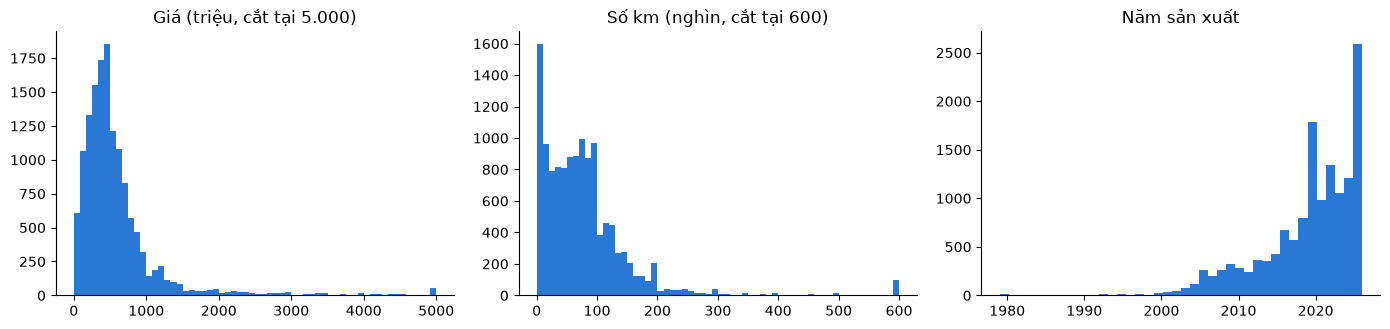

       price_tr  mileage_km   mfdate
count   14143.0     12665.0  14144.0
mean      600.0     81495.4   2019.0
std       737.9     96838.3      6.2
min         0.4         1.0   1979.0
0.1%        6.0         1.0   1984.0
1%         34.7         7.0   2001.0
50%       450.0     67000.0   2021.0
99%      3629.0    498484.5   2026.0
99.9%    7391.9   1000000.0   2026.0
max     40000.0   1000000.0   2026.0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].hist(df["price_tr"].dropna().clip(upper=5000), bins=60, color=BLUE)
axes[0].set_title("Giá (triệu, cắt tại 5.000)")
axes[1].hist(df["mileage_km"].dropna().clip(upper=600000) / 1e3, bins=60, color=BLUE)
axes[1].set_title("Số km (nghìn, cắt tại 600)")
axes[2].hist(df["mfdate"].dropna(), bins=40, color=BLUE)
axes[2].set_title("Năm sản xuất")
fig.tight_layout()
plt.show()

print(df[["price_tr", "mileage_km", "mfdate"]].describe(percentiles=[.001, .01, .5, .99, .999]).round(1))

**Quy tắc (dựa trên hiểu biết thực tế, không dùng cắt phần trăm máy móc):**

| Cột | Quy tắc | Lý do |
|---|---|---|
| `price_tr` | loại nếu < 20 triệu hoặc > 10.000 triệu | Xe ô tô dưới 20 triệu gần như không tồn tại (thường là gõ thiếu số 0, hoặc đăng giá đặt cọc); trên 10 tỷ là gõ thừa số 0 hoặc xe siêu hiếm không đại diện cho thị trường. Không thể biết giá đúng nên **loại** thay vì sửa. |
| `price_tr` | loại nếu chữ số của giá là dãy liên tiếp (`123.456.789`, `12.345.678`, `23.456.789`...) | Giá là ô gõ tự do; người bán gõ dãy số này khi không muốn công khai giá ("liên hệ"). Đây là **giá giả**, không phải giá xe. Các giá như `399.999.999` hay `888.888.888` thì **giữ**: đó là cách định giá tâm lý (gần 400 triệu) hoặc số đẹp, vẫn là giá thật. |
| `price_tr` | loại nếu < 30% giá trung vị của xe cùng hãng, dòng, năm sản xuất (nhóm ≥ 3 xe) | Giá thấp bất thường so với chính mẫu xe đó thường là **tiền trả trước / đặt cọc**, không phải giá xe (ví dụ VinFast VF3 2026 mới rao 28 triệu). Xem mục 5.1. |
| `condition_ad` | ghi "Mới" nhưng xe **hơn 3 năm tuổi** → đổi thành "Đã sử dụng", số km coi là thiếu | Xe tồn kho ở đại lý có thể "mới" dù đời 1-3 năm trước (ví dụ BMW đời 2023 chưa lăn bánh), nhưng một chiếc Hyundai Tucson đời 2011 rao "mới" giá 255 triệu là ghi sai tình trạng. Nếu giữ nhãn "Mới", bước 6 sẽ điền 0 km cho xe này, sai hoàn toàn. |
| `mileage_km` | xe đã dùng mà > 500.000 km → thiếu | Vượt xa mức xe dân dụng chạy được, nhiều khả năng nhập thừa số 0 (ví dụ 1.000.000) |
| `mileage_km` | xe đã dùng, tuổi ≥ 2 năm mà < 100 km → thiếu | Xe 5 năm tuổi không thể chạy 10 km: người đăng nhập theo đơn vị nghìn km (10 = 10.000 km) hoặc nhập bừa. Không biết chắc đơn vị nên coi là thiếu rồi điền theo đời xe, an toàn hơn tự nhân 1000. |
| `mileage_km` | xe đã dùng, > 100.000 km/năm (km chia tuổi, tối thiểu 1 năm) → thiếu | Xe đời 1 tuổi mà đi 480.000 km là bất khả thi (xe dịch vụ chạy nhiều cũng chỉ khoảng 80.000-100.000 km/năm) |
| `mfdate` | giữ nguyên | Dải 1979-2026 hợp lệ; xe đời 2026 là xe năm nay/mới |

In [9]:
n0 = len(df)

# Biến mục tiêu: bỏ dòng thiếu giá + giá bất hợp lý
bad_price = df["price_tr"].isna() | (df["price_tr"] < 20) | (df["price_tr"] > 10_000)
print(f"Loại {bad_price.sum()} dòng giá thiếu/bất hợp lý ({df['price_tr'].isna().sum()} thiếu, "
      f"{(df['price_tr'] < 20).sum()} < 20 triệu, {(df['price_tr'] > 10_000).sum()} > 10.000 triệu)")
df = df[~bad_price].reset_index(drop=True)
FUNNEL.append(("Loại giá thiếu, < 20 triệu, > 10 tỷ", len(df)))

# Giá giả: chữ số là dãy tăng liên tiếp (123456789, 12345678, 23456789, 1234567890...)
digits = df["price"].astype("int64").astype(str)
fake_price = digits.map(lambda s: len(s) >= 7 and s in "1234567890")
print(f"Loại {fake_price.sum()} tin có giá giả dạng dãy số liên tiếp:", sorted(digits[fake_price].unique()))
df = df[~fake_price].reset_index(drop=True)
FUNNEL.append(("Loại giá giả 123.456.789", len(df)))

df["age"] = CURRENT_YEAR - df["mfdate"]

# Tình trạng: "Mới" nhưng hơn 3 năm tuổi là ghi sai -> "Đã sử dụng" (số km đang trống, sẽ được điền ở mục 6)
wrong_new = (df["condition_ad"] == "Mới") & (df["age"] > 3)
print(f"\nXe ghi 'Mới' nhưng hơn 3 năm tuổi: {wrong_new.sum()} -> đổi thành 'Đã sử dụng'")
display(df.loc[wrong_new, ["carbrand", "carmodel", "mfdate", "condition_ad", "mileage_km", "price_tr"]])
df.loc[wrong_new, "condition_ad"] = "Đã sử dụng"

# Số km của xe đã dùng
used = df["condition_ad"] == "Đã sử dụng"
bad_km_high = used & (df["mileage_km"] > 500_000)
bad_km_low = used & (df["age"] >= 2) & (df["mileage_km"] < 100)
bad_km_rate = used & (df["mileage_km"] / df["age"].clip(lower=1) > 100_000) & ~bad_km_high
print(f"Số km bất hợp lý của xe đã dùng: {bad_km_high.sum()} quá cao, {bad_km_low.sum()} quá thấp, "
      f"{bad_km_rate.sum()} vượt 100.000 km/năm -> chuyển thành thiếu")
df.loc[bad_km_high | bad_km_low | bad_km_rate, "mileage_km"] = np.nan

print("Còn lại:", df.shape, f"(mất {n0 - len(df)} dòng)")

Loại 64 dòng giá thiếu/bất hợp lý (1 thiếu, 62 < 20 triệu, 1 > 10.000 triệu)
Loại 14 tin có giá giả dạng dãy số liên tiếp: ['123456789', '1234567890', '23456789', '234567890']

Xe ghi 'Mới' nhưng hơn 3 năm tuổi: 6 -> đổi thành 'Đã sử dụng'


,carbrand,carmodel,mfdate,condition_ad,mileage_km,price_tr
709,Kia,Carnival,2019,Mới,NaN,535.0
3197,Changan,Dòng khác,2018,Mới,NaN,105.0
5436,Hãng khác,Dòng khác,2020,Mới,NaN,110.0
9229,Hyundai,Tucson,2011,Mới,NaN,255.0
11749,Nissan,X Trail,2018,Mới,NaN,550.0
13277,Hyundai,Grand i10,2021,Mới,NaN,290.0


Số km bất hợp lý của xe đã dùng: 106 quá cao, 447 quá thấp, 25 vượt 100.000 km/năm -> chuyển thành thiếu
Còn lại: (14066, 14) (mất 78 dòng)


### 5.1 Giá trả trước / đặt cọc (nhãn sai)
Ngưỡng 20 triệu ở trên chỉ bắt được lỗi gõ thiếu số. Vẫn còn nhiều tin mà "giá" thực ra là **số tiền trả trước hoặc đặt cọc** (người bán ghi khoản trả trước cho dễ thu hút, phần còn lại trả góp), ví dụ xe đời 2025-2026 còn mới mà giá chỉ 30-100 triệu. Một con số tuyệt đối không bắt được trường hợp này vì 100 triệu là hợp lý với xe 20 năm tuổi nhưng vô lý với xe 1 năm tuổi.

**Quy tắc:** so với chính mẫu xe đó. Loại tin có giá **thấp hơn 30% giá trung vị của các xe cùng hãng, dòng và năm sản xuất**, chỉ xét nhóm có ít nhất 3 xe để trung vị đủ tin cậy. Không xe nào mất giá 70% so với xe cùng đời chỉ vì tình trạng hay số km.

**Vì sao quan trọng:** đây là **nhãn sai** nằm đúng ở biến cần dự đoán. Mô hình dự đoán đúng giá xe nhưng bị chấm là sai hàng trăm phần trăm, và phần lớn rơi vào phân khúc `< 200 triệu`, làm sai số của phân khúc này cao giả tạo.

> **Ghi chú về rò rỉ dữ liệu:** quy tắc dùng giá (biến mục tiêu) trên toàn bộ dữ liệu. Điều này chấp nhận được vì đây là bước **sửa lỗi nhãn** (loại dòng có đáp án sai), không phải tạo đặc trưng: không có thông tin nào từ giá được đưa vào đầu vào của mô hình. Cách chặt chẽ hơn là crawl thêm phần mô tả tin đăng và lọc theo từ khóa "trả trước", "góp", "cọc".

In [10]:
# Giá rao quá thấp so với xe cùng hãng-dòng-năm: thường là tiền trả trước / đặt cọc, không phải giá xe
grp = df.groupby(["carbrand", "carmodel", "mfdate"])["price_tr"]
ref, n_grp = grp.transform("median"), grp.transform("size")
deposit = (n_grp >= 3) & (df["price_tr"] < 0.3 * ref)
print(f"Loại {deposit.sum()} tin nghi giá trả trước/đặt cọc "
      f"({(df.loc[deposit, 'price_tr'] < 200).mean():.0%} trong số đó có giá < 200 triệu)")
display(df.loc[deposit, ["carbrand", "carmodel", "mfdate", "condition_ad", "price_tr"]]
          .assign(**{"trung vị nhóm": ref[deposit]})
          .sort_values("trung vị nhóm", ascending=False).head(10))
df = df[~deposit].reset_index(drop=True)
FUNNEL.append(("Loại giá trả trước / đặt cọc", len(df)))
print("Còn lại:", df.shape)

Loại 129 tin nghi giá trả trước/đặt cọc (94% trong số đó có giá < 200 triệu)


,carbrand,carmodel,mfdate,condition_ad,price_tr,trung vị nhóm
7262,Toyota,Camry,2026,Đã sử dụng,300.000000,1400.0
8610,Ford,Everest,2026,Đã sử dụng,320.000000,1325.0
4765,Toyota,Fortuner,2026,Mới,125.000000,1249.0
7576,Ford,Everest,2025,Đã sử dụng,111.111111,1235.0
9309,Ford,Everest,2024,Đã sử dụng,300.000000,1145.0
12494,Hyundai,Santa Fe,2025,Mới,220.000000,959.0
9551,Hyundai,Santa Fe,2025,Mới,240.000000,959.0
4265,Toyota,Fortuner,2024,Đã sử dụng,250.000000,930.0
12625,Mercedes Benz,E Class,2019,Đã sử dụng,156.000000,889.0
13991,BYD,Sealion 6,2026,Mới,145.000000,884.0


Còn lại: (13937, 14)


In [11]:
# Kiểm tra IQR trên log(giá) chỉ để THAM KHẢO: ngoại lệ thống kê, không xóa
lp = np.log(df["price_tr"])
q1, q3 = lp.quantile([.25, .75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
out = (lp < lo) | (lp > hi)
print(f"Ngoại lệ theo IQR(log giá): {out.sum()} dòng ({out.mean():.1%}), khoảng hợp lệ {np.exp(lo):.0f}-{np.exp(hi):.0f} triệu")
df.loc[out, ["carbrand", "carmodel", "mfdate", "price_tr"]].sort_values("price_tr", ascending=False).head(5)

Ngoại lệ theo IQR(log giá): 696 dòng (5.0%), khoảng hợp lệ 76-2552 triệu


,carbrand,carmodel,mfdate,price_tr
12860,Mercedes Benz,E Class,2023,9769.0
12033,Lexus,LX 600,2026,9700.0
3232,Lexus,LX,2024,9000.0
7896,Bentley,Flying Spur,2021,9000.0
13618,LandRover,Range Rover,2022,8900.0


Các ngoại lệ IQR còn lại chủ yếu là xe sang thật (Mercedes, BMW, Lexus, Porsche...) hoặc xe cổ rất rẻ. Đây là thông tin thật của thị trường nên **giữ nguyên**; ảnh hưởng của chúng lên mô hình được giảm bằng log-transform ở mục 7.

## 6. Xử lý giá trị thiếu

Thứ tự: **cột số suy ra từ cấu trúc** → **cột phân loại suy ra từ dòng xe** → **cột để nhãn "Không rõ"**.

**Cột đánh dấu `mileage_missing`:** với xe đã dùng, số km được điền bằng trung vị theo đời xe. Giá trị điền là "đoán trung bình", không phải số đo thật. Nếu chỉ điền rồi bỏ qua, mô hình sẽ tin con số này như mọi xe khác. Thêm cột `mileage_missing` (1 = km gốc bị thiếu hoặc không tin được, đã điền; 0 = km do người bán khai) để mô hình **biết** dòng nào là ước lượng và tự học mức độ tin cậy. Việc người bán không khai số km cũng có thể là một tín hiệu về giá. Xe mới không đánh dấu vì 0 km là giá trị đúng, không phải ước lượng.

In [12]:
used = df["condition_ad"] == "Đã sử dụng"

# --- mileage_km ---
# Đánh dấu TRƯỚC khi điền: xe đã dùng có km thiếu (bỏ trống hoặc bị loại ở mục 5)
df["mileage_missing"] = (used & df["mileage_km"].isna()).astype(int)

# (a) xe mới: 0 km (thiếu có cấu trúc)
df.loc[~used & df["mileage_km"].isna(), "mileage_km"] = 0

# (b) xe đã dùng thiếu km: trung vị theo đời xe. Dùng trung vị (không phải trung bình) vì số km lệch phải mạnh.
med_by_year = df[used].groupby("mfdate")["mileage_km"].median()
fill = df["mfdate"].map(med_by_year)
fill = fill.fillna(df.loc[used, "mileage_km"].median())     # năm hiếm chưa có trung vị
df.loc[used & df["mileage_km"].isna(), "mileage_km"] = fill
print(f"mileage_km: điền {df['mileage_missing'].sum()} xe đã dùng bằng trung vị theo đời xe "
      f"({df['mileage_missing'].mean():.1%} số dòng, đánh dấu ở cột mileage_missing)")
print("mileage_km còn thiếu:", df["mileage_km"].isna().sum())

mileage_km: điền 814 xe đã dùng bằng trung vị theo đời xe (5.8% số dòng, đánh dấu ở cột mileage_missing)
mileage_km còn thiếu: 0


In [13]:
def fill_by_group_mode(frame, col, brand_fallback=True):
    # Điền thiếu bằng giá trị phổ biến nhất (mode) theo 2 cấp:
    #   1) cùng hãng + dòng xe (bỏ qua 'Dòng khác' vì nhãn này gộp nhiều xe không liên quan)
    #   2) cùng hãng, chỉ khi brand_fallback=True
    # Trả về cột đã điền và số dòng được điền ở mỗi cấp.
    def mode(s):
        s = s.dropna()
        return s.mode().iat[0] if len(s) else np.nan

    out = frame[col].copy()
    miss = out.isna()
    specific = frame["carmodel"] != "Dòng khác"
    by_model = frame[specific].groupby(["carbrand", "carmodel"])[col].transform(mode).reindex(frame.index)
    out = out.fillna(by_model)
    n_model = (miss & out.notna()).sum()
    n_brand = 0
    if brand_fallback:
        left = out.isna()
        out = out.fillna(frame.groupby("carbrand")[col].transform(mode))
        n_brand = (left & out.notna()).sum()
    return out, {"thiếu": miss.sum(), "điền theo dòng xe": n_model, "điền theo hãng": n_brand,
                 "còn lại": out.isna().sum()}

report = {}
# --- carseats: số chỗ do dòng xe quyết định; sai lệch theo hãng ít hại (đa số xe 5 chỗ) nên cho phép lùi về hãng
df["carseats"], report["carseats"] = fill_by_group_mode(df, "carseats")
df["carseats"] = df["carseats"].fillna(df["carseats"].mode().iat[0])   # hãng chỉ có xe thiếu thông tin

# --- cartype: KHÔNG lùi về hãng (một hãng bán cả sedan, SUV, bán tải); không suy ra được -> "Không rõ"
df["cartype"], report["cartype"] = fill_by_group_mode(df, "cartype", brand_fallback=False)
df["cartype"] = df["cartype"].fillna("Không rõ")

# --- carorigin: quá nhiều thiếu, không đoán được -> nhãn riêng
report["carorigin"] = {"thiếu": df["carorigin"].isna().sum(), "điền theo dòng xe": 0, "điền theo hãng": 0,
                       "còn lại": df["carorigin"].isna().sum()}
df["carorigin"] = df["carorigin"].fillna("Không rõ")

display(pd.DataFrame(report).T.rename(columns={"còn lại": "→ nhãn 'Không rõ' / mode chung"}))
print("Thiếu còn lại:", int(df.isna().sum().sum()))

,thiếu,điền theo dòng xe,điền theo hãng,→ nhãn 'Không rõ' / mode chung
carseats,3539,3352,183,4
cartype,4579,4336,0,243
carorigin,5787,0,0,5787


Thiếu còn lại: 0


In [14]:
# Kiểm tra: việc điền có làm méo phân phối cột cartype không (so với raw, chỉ phần đã biết)
before = raw["cartype"].replace(["N/A"], np.nan).value_counts(normalize=True)
after = df["cartype"].value_counts(normalize=True)
pd.DataFrame({"trước (chỉ phần có)": before, "sau điền": after}).round(3).sort_values("sau điền", ascending=False)

,trước (chỉ phần có),sau điền
cartype,,
SUV / Cross over,0.410,0.389
Sedan,0.241,0.252
Minivan (MPV),0.125,0.141
Hatchback,0.076,0.084
Pick-up (bán tải),0.080,0.062
Van,0.045,0.036
Không rõ,NaN,0.017
Kiểu dáng khác,0.015,0.011
Coupe (2 cửa),0.005,0.004


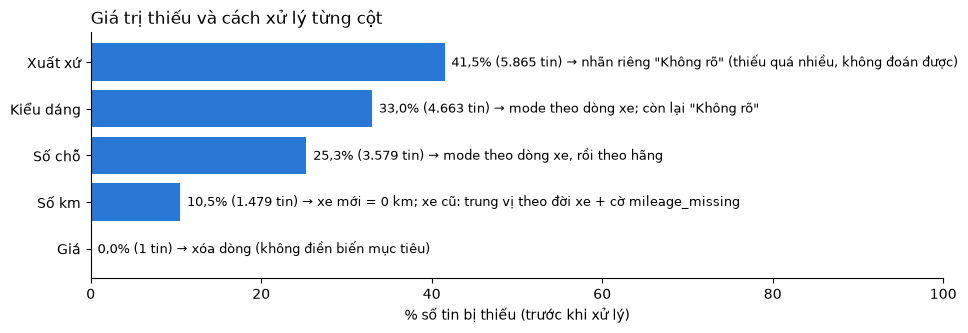

In [15]:
# Tóm tắt: tỉ lệ thiếu của từng cột (phân tích ở mục 4) và cách đã xử lý
COL_VI = {"carorigin": "Xuất xứ", "cartype": "Kiểu dáng", "carseats": "Số chỗ", "mileage_km": "Số km", "price_tr": "Giá"}
METHOD = {"carorigin": 'nhãn riêng "Không rõ" (thiếu quá nhiều, không đoán được)',
          "cartype": 'mode theo dòng xe; còn lại "Không rõ"',
          "carseats": "mode theo dòng xe, rồi theo hãng",
          "mileage_km": "xe mới = 0 km; xe cũ: trung vị theo đời xe + cờ mileage_missing",
          "price_tr": "xóa dòng (không điền biến mục tiêu)"}
mb = miss_before.loc[[c for c in COL_VI if c in miss_before.index and miss_before.loc[c, "thiếu"] > 0]]
mb = mb.sort_values("%")

fig, ax = plt.subplots(figsize=(11, 3.2))
y = np.arange(len(mb))
ax.barh(y, mb["%"], color=BLUE)
for i, (c, r) in enumerate(mb.iterrows()):
    num = f"{r['%']:.1f}%".replace(".", ",") + f" ({int(r['thiếu']):,} tin)".replace(",", ".")   # chỉ định dạng phần số
    ax.text(r["%"] + 0.8, i, f"{num} → {METHOD[c]}", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels([COL_VI[c] for c in mb.index])
ax.set_xlim(0, 100); ax.set_xlabel("% số tin bị thiếu (trước khi xử lý)")
ax.set_title("Giá trị thiếu và cách xử lý từng cột", loc="left"); ax.grid(axis="y", visible=False)
save(fig, "p02_thieu_va_cach_xu_ly"); plt.show()

**Vì sao `cartype` không lùi về cấp hãng còn `carseats` thì có?** Trong cùng một dòng xe, kiểu dáng gần như cố định (trung vị độ thuần nhất = 100%), nên điền theo dòng xe rất đáng tin. Nhưng một hãng bán đủ loại: Ford có cả Ranger (bán tải), Everest (SUV), Focus (sedan). Lấy kiểu dáng phổ biến nhất của hãng gán cho một xe "Dòng khác" là đoán mò, nên những xe này được ghi **"Không rõ"**. Số chỗ thì khác: đa số xe 5 chỗ, đoán sai theo hãng thường chỉ lệch 5 ↔ 7 chỗ và mô hình vẫn có hãng, dòng xe để bù lại.

> **Lưu ý về rò rỉ dữ liệu (data leakage):** việc điền thiếu ở mục này dùng thống kê của **toàn bộ** tập dữ liệu (mode theo dòng xe, trung vị theo đời xe) trước khi chia train/test. Rủi ro thấp vì các thống kê này chỉ dựa trên **đặc trưng**, không dùng giá (biến mục tiêu), và là quy tắc theo nhóm lớn. Trong triển khai thực tế nên fit các thống kê này trên tập train rồi áp lên test.

## 7. Biến đổi, gộp nhãn hiếm và tạo đặc trưng

### 7.1 Biến đổi log cho giá
Giá lệch phải mạnh (đa số xe 200-800 triệu, vài xe vài tỷ). Phân phối lệch làm mô hình hồi quy bị kéo bởi vài điểm lớn và sai số lớn dồn vào xe đắt. `log(giá)` đưa phân phối về gần đối xứng và biến chênh lệch tuyệt đối thành chênh lệch **tương đối** (xe 100 triệu → 150 triệu và 1 tỷ → 1,5 tỷ đều là +50%), khớp với cách người mua nghĩ về giá.

Độ lệch (skewness): giá gốc = 5.08, log(giá) = -0.20


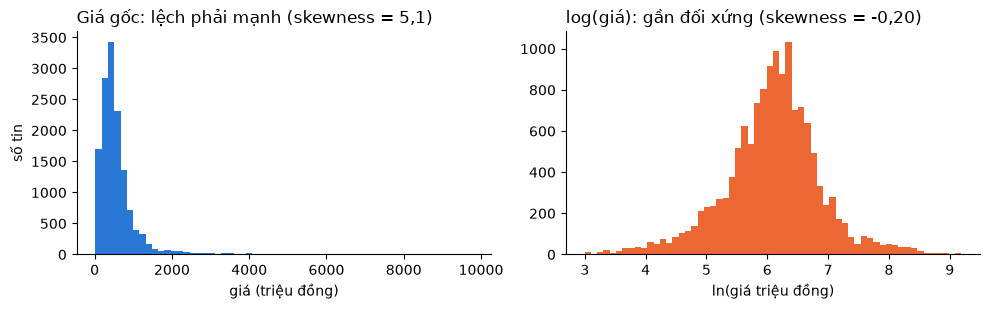

In [16]:
from scipy.stats import skew
df["price_log"] = np.log(df["price_tr"])
print(f"Độ lệch (skewness): giá gốc = {skew(df['price_tr']):.2f}, log(giá) = {skew(df['price_log']):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(df["price_tr"], bins=60, color=BLUE)
axes[0].set_title(f"Giá gốc: lệch phải mạnh (skewness = {skew(df['price_tr']):.1f})".replace(".", ","), loc="left")
axes[0].set_xlabel("giá (triệu đồng)"); axes[0].set_ylabel("số tin")
axes[1].hist(df["price_log"], bins=60, color=ORANGE)
axes[1].set_title(f"log(giá): gần đối xứng (skewness = {skew(df['price_log']):.2f})".replace(".", ","), loc="left")
axes[1].set_xlabel("ln(giá triệu đồng)")
fig.tight_layout()
save(fig, "p03_gia_va_log_gia"); plt.show()

**Gắn với bài toán dự đoán giá:** `price_log` sẽ là **biến mục tiêu** mà mô hình học. Sau khi dự đoán chỉ cần `exp()` để đổi về triệu đồng. Lựa chọn này được kiểm chứng bằng số liệu ở `model.ipynb` (mục 7): so sánh huấn luyện Random Forest trên giá gốc và trên log giá bằng cross-validation **trên tập train**.

### 7.2 Gộp nhãn hiếm theo cấp (dòng xe → hãng → nhóm hãng)
`carbrand` có ~70 hãng, `carmodel` hơn 500 tổ hợp hãng + dòng, nhiều nhãn chỉ có 1-5 tin. One-hot nguyên vẹn sinh hàng trăm cột thưa, mô hình học quy luật từ vài mẫu là nhiễu (overfit), và nhãn chỉ xuất hiện ở test thì mô hình không biết xử lý. Vì vậy cần gộp nhãn hiếm, nhưng **gộp vào đâu** quyết định mô hình còn giữ được bao nhiêu thông tin.

**Cách cũ và vấn đề:** mọi dòng xe hiếm của mọi hãng gộp chung vào **một** nhãn `"Dòng khác"`, mọi hãng hiếm gộp vào `"Hãng khác"`. Nhãn `"Dòng khác"` chiếm 17% dữ liệu nhưng tới **65% số xe trên 2 tỷ**: một chiếc Mercedes G63 và một chiếc Kia đời cũ mang cùng nhãn. `"Hãng khác"` trộn Bentley, Maybach với Wuling, Gaz. Đây chính là hai phân khúc mô hình dự đoán kém nhất.

**Cách mới (gộp theo cấp, mỗi xe lùi về nhóm gần nhất còn đủ mẫu):**

| Cấp | Quy tắc | Ví dụ |
|---|---|---|
| Dòng xe | giữ `Hãng + Dòng` nếu có ≥ 10 tin | `Toyota Vios` |
| → Hãng | dòng hiếm hoặc `Dòng khác` → `"<Hãng> - dòng khác"` | `Mercedes Benz - dòng khác` |
| Hãng | giữ hãng nếu có ≥ 30 tin | `Volvo`, `Subaru` |
| → Nhóm hãng | hãng hiếm → `"Hãng cao cấp khác"` hoặc `"Hãng phổ thông khác"` | Bentley → cao cấp; Wuling → phổ thông |

- **Lùi về hãng** giữ lại thông tin quan trọng nhất còn biết được: một dòng Mercedes hiếm vẫn là Mercedes.
- **Tách hãng hiếm thành cao cấp / phổ thông** theo **định vị thương hiệu** (hiểu biết thị trường: Bentley, Maybach, Aston Martin, Maserati, Jaguar, Volvo...), **không** dựa vào giá trong dữ liệu, để không dùng biến mục tiêu khi tạo đặc trưng.
- **Ngưỡng 30 / 10** (trước đây 50 / 30): chọn bằng 5-fold cross-validation **chỉ trên phần train** (mục 7.4). Ngưỡng 10 tin vẫn đủ để mỗi cột one-hot có vài mẫu trong mỗi fold; Ridge có điều chuẩn L2 và rừng cây có `min_samples_leaf` để chống overfit trên nhãn nhỏ.

Giữ lại cột gốc `carbrand`, `carmodel` để tra cứu; cột `*_grp` dùng cho mô hình.

In [17]:
BRAND_MIN, MODEL_MIN = 30, 10
# Thương hiệu xe sang / hiệu năng cao (định vị thị trường, không dựa vào giá trong dữ liệu)
LUXURY_BRANDS = {"Bentley", "Rolls Royce", "Maybach", "Aston Martin", "Ferrari", "Lamborghini", "McLaren",
                 "Maserati", "Cadillac", "Lincoln", "Hummer", "Jaguar", "Infiniti", "Acura", "Volvo",
                 "Alfa Romeo", "MINI", "Jeep", "Genesis", "Lotus"}


def group_hierarchical(frame, brand_min, model_min):
    # Hãng hiếm -> nhóm hãng (cao cấp / phổ thông); dòng hiếm hoặc 'Dòng khác' -> '<hãng đã gộp> - dòng khác'
    brand = frame["carbrand"]
    brand_other = np.where(brand.isin(LUXURY_BRANDS), "Hãng cao cấp khác", "Hãng phổ thông khác")
    brand_grp = brand.where(brand.map(brand.value_counts()) >= brand_min, brand_other)

    full = brand + " " + frame["carmodel"]
    keep = (full.map(full.value_counts()) >= model_min) & (frame["carmodel"] != "Dòng khác")
    model_grp = full.where(keep, brand_grp + " - dòng khác")
    return brand_grp, model_grp


df["carbrand_grp"], df["carmodel_grp"] = group_hierarchical(df, BRAND_MIN, MODEL_MIN)

print(f"carbrand: {df['carbrand'].nunique()} hãng -> {df['carbrand_grp'].nunique()} nhóm")
print(f"carmodel: {(df['carbrand'] + df['carmodel']).nunique()} tổ hợp hãng+dòng -> {df['carmodel_grp'].nunique()} nhóm")
print(f"Tỉ lệ xe mang nhãn '... - dòng khác': {df['carmodel_grp'].str.endswith('dòng khác').mean():.1%}")

# Kiểm tra sau khi gộp (chỉ để mô tả): hai nhóm hãng hiếm có mức giá khác nhau rõ rệt
rare_brand = df["carbrand_grp"].isin(["Hãng cao cấp khác", "Hãng phổ thông khác"])
display(df[rare_brand].groupby("carbrand_grp")
          .agg(số_tin=("price_tr", "size"), số_hãng=("carbrand", "nunique"), giá_trung_vị=("price_tr", "median"),
               các_hãng=("carbrand", lambda s: ", ".join(s.value_counts().index[:8]))))

carbrand: 69 hãng -> 28 nhóm
carmodel: 509 tổ hợp hãng+dòng -> 214 nhóm
Tỉ lệ xe mang nhãn '... - dòng khác': 8.9%


,số_tin,số_hãng,giá_trung_vị,các_hãng
carbrand_grp,,,,
Hãng cao cấp khác,93,13,1000.0,"MINI, Jeep, Acura, Jaguar, Bentley, Infiniti, ..."
Hãng phổ thông khác,188,30,390.0,"Skoda, Geely, Chery, Dongfeng, Ssangyong, Wuli..."


### 7.3 Tạo đặc trưng
- `age` = 2026 − năm sản xuất. Tuổi xe có ý nghĩa trực tiếp hơn một con số năm tuyệt đối, và xe đời mới/cũ đều khấu hao theo tuổi.
- `km_per_year` = km / max(tuổi, 1). Xe 5 năm đi 50.000 km (10.000 km/năm) khác hẳn xe 5 năm đi 150.000 km (30.000 km/năm, nhiều khả năng chạy dịch vụ) dù cùng tuổi. Chặn mẫu số tối thiểu 1 để xe đời 2026 (age = 0) không chia cho 0.
- `mileage_missing` (đã tạo ở mục 6): 1 nếu số km là giá trị điền.
- `province` (tỉnh/thành dạng slug, đã tạo ở mục 3): vị trí của tin đăng. Mục 7.4 kiểm tra xem vị trí có giúp dự đoán không.

**Gợi ý cho bước mô hình:** các biến đổi phi tuyến như `age²` hay `log(km)` chỉ cần cho **mô hình tuyến tính** (Ridge), để quan hệ cong (xe mất giá nhanh những năm đầu rồi chậm lại) trở nên gần tuyến tính. **Mô hình cây** (Decision Tree, Random Forest) chỉ so sánh ngưỡng nên không bị ảnh hưởng bởi biến đổi đơn điệu: `age` và `age²` mang **cùng một thông tin**. Đưa cả hai vào cây không làm mô hình tốt hơn, chỉ chia đôi độ quan trọng đặc trưng và gây hiểu nhầm khi đọc biểu đồ. Vì vậy file xuất ra chỉ chứa đặc trưng gốc; mỗi mô hình tự thêm biến đổi nó cần.

In [18]:
df["km_per_year"] = df["mileage_km"] / df["age"].clip(lower=1)   # age đã tính ở mục 5
df["carseats"] = df["carseats"].astype(int)
df["mfdate"] = df["mfdate"].astype(int)
df["age"] = df["age"].astype(int)
df[["age", "mileage_km", "km_per_year", "mileage_missing"]].describe().round(1)

,age,mileage_km,km_per_year,mileage_missing
count,13937.0,13937.0,13937.0,13937.0
mean,7.0,70515.2,12132.7,0.1
std,6.2,61669.9,10763.6,0.2
min,0.0,0.0,0.0,0.0
25%,2.0,22000.0,6000.0,0.0
50%,5.0,62000.0,10142.9,0.0
75%,10.0,100000.0,15593.7,0.0
max,47.0,500000.0,100000.0,1.0


### 7.4 Kiểm chứng cách gộp nhãn bằng cross-validation trên tập train
Để chọn cách gộp và ngưỡng bằng số liệu thay vì cảm tính, so sánh 3 phương án với hai mô hình sẽ dùng (Ridge và Random Forest):

- **Cũ:** một nhãn `"Dòng khác"` / `"Hãng khác"` chung, ngưỡng 50 / 30
- **Gộp theo cấp, ngưỡng cũ:** lùi về hãng + tách nhóm hãng, ngưỡng 50 / 30
- **Gộp theo cấp, ngưỡng mới:** như trên, ngưỡng 30 / 10 (phương án được chọn)

**Cách làm đúng để không rò rỉ:** dùng đúng cách chia train/test của `model.ipynb` (80/20, phân tầng theo phân khúc giá, `random_state=42`) và **chỉ dùng phần train** cho 5-fold CV. Tập test không tham gia lựa chọn. Rừng cây ở đây dùng 100 cây cho nhanh nên số liệu tuyệt đối hơi khác `model.ipynb`; điều cần xem là **chênh lệch giữa các phương án**. Đặc trưng số giống `model.ipynb`.

In [19]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

SEG_BINS = [0, 200, 500, 1000, 2000, np.inf]
SEG_LABELS = ["< 200 triệu", "200-500", "500-1.000", "1-2 tỷ", "> 2 tỷ"]
seg_all = pd.cut(df["price_tr"], bins=SEG_BINS, labels=SEG_LABELS, right=False).astype(str)
idx_tr, _ = train_test_split(df.index, test_size=0.2, stratify=seg_all, random_state=RANDOM_STATE)


def old_grouping(frame, brand_min=50, model_min=30):
    vc_b = frame["carbrand"].value_counts()
    full = frame["carbrand"] + " " + frame["carmodel"]
    return (frame["carbrand"].where(frame["carbrand"].map(vc_b) >= brand_min, "Hãng khác"),
            full.where(full.map(full.value_counts()) >= model_min, "Dòng khác"))


def cv_mape(brand_grp, model_grp, extra_cat=()):
    d = df.loc[idx_tr].assign(b=brand_grp.loc[idx_tr], m=model_grp.loc[idx_tr],
                              age_sq=lambda x: x["age"] ** 2, log_km=lambda x: np.log1p(x["mileage_km"]),
                              log_kpy=lambda x: np.log1p(x["km_per_year"]))
    cat = ["b", "m", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", *extra_cat]
    num = ["age", "age_sq", "log_km", "carseats", "log_kpy"]
    y, p, seg = d["price_log"].values, d["price_tr"].values, seg_all.loc[idx_tr].values
    res = {}
    for name, make_model in [("Ridge", lambda: Ridge(alpha=0.3)),
                             ("Random Forest", lambda: RandomForestRegressor(100, max_depth=30, max_features=0.33,
                                                                             random_state=RANDOM_STATE, n_jobs=-1))]:
        oof = np.zeros(len(d))
        for a, b in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(d, seg):
            prep = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat), ("n", StandardScaler(), num)])
            m = make_model().fit(prep.fit_transform(d.iloc[a]), y[a])     # fit chỉ trên phần train của fold
            oof[b] = np.exp(m.predict(prep.transform(d.iloc[b])))
        ape = np.abs(oof - p) / p
        res[(name, "MAPE")] = ape.mean()
        res.update({(name, s): ape[seg == s].mean() for s in ["< 200 triệu", "> 2 tỷ"]})
    return res


variants = {
    "Cũ (50 / 30)": old_grouping(df),
    "Gộp theo cấp (50 / 30)": group_hierarchical(df, 50, 30),
    "Gộp theo cấp (30 / 10) - chọn": group_hierarchical(df, BRAND_MIN, MODEL_MIN),
}
cmp = pd.DataFrame({k: cv_mape(*v) for k, v in variants.items()}).T
cmp.columns = pd.MultiIndex.from_tuples(cmp.columns)
cmp.round(3)

Ridge                    Random Forest                   
                                MAPE < 200 triệu > 2 tỷ          MAPE < 200 triệu > 2 tỷ
Cũ (50 / 30)                   0.219       0.522  0.430         0.163       0.374  0.292
Gộp theo cấp (50 / 30)         0.206       0.474  0.392         0.163       0.361  0.278
Gộp theo cấp (30 / 10) - chọn  0.189       0.449  0.322         0.161       0.359  0.287

**Đọc kết quả** (MAPE càng thấp càng tốt):
- **Ridge cải thiện rõ rệt:** MAPE tổng giảm từ khoảng 0,22 xuống 0,19; phân khúc > 2 tỷ giảm từ khoảng 0,43 xuống 0,32. Mô hình tuyến tính chỉ có **một hệ số cho mỗi nhãn**. Khi xe sang và xe rẻ bị dồn chung một nhãn `"Dòng khác"`, hệ số đó là mức trung bình vô nghĩa. Lùi về hãng cho mỗi nhóm một mức giá hợp lý hơn.
- **Random Forest cải thiện nhẹ:** MAPE tổng giảm khoảng 0,002; phân khúc < 200 triệu giảm khoảng 0,015; phân khúc > 2 tỷ gần như không đổi (dao động ±0,01 giữa các phương án, trong mức nhiễu của CV). Rừng cây vốn bù được phần thông tin bị mất bằng cách kết hợp các đặc trưng khác (tuổi xe, kiểu dáng, hộp số), nên được lợi ít hơn.
- Không phương án nào làm mô hình xấu đi. Vì vậy **chọn gộp theo cấp với ngưỡng 30 / 10**. Sai số còn lại ở xe sang chủ yếu do dữ liệu thiếu phiên bản và trang bị xe, không xử lý được bằng tiền xử lý.

**Có nên dùng vị trí (miền, tỉnh/thành) làm đặc trưng?** Dùng cùng cách đánh giá, cách gộp nhãn đã chọn, chỉ thêm vị trí. Miền được suy ra từ tỉnh ngay tại đây (không lưu thành cột). Với tỉnh/thành, các tỉnh có dưới 100 tin được gộp thành `"Tỉnh khác - <miền>"` (cùng ý tưởng gộp theo cấp ở mục 7.2).

In [20]:
bg, mg = group_hierarchical(df, BRAND_MIN, MODEL_MIN)
df["region"] = df["province"].map(REGION)          # cột tạm cho thí nghiệm, không xuất ra file
prov_vc = df["province"].value_counts()
df["province_grp"] = df["province"].where(df["province"].map(prov_vc) >= 100, "Tỉnh khác - " + df["region"])
loc_cmp = pd.DataFrame({
    "Không dùng vị trí": cv_mape(bg, mg),
    "+ miền (3 nhóm)": cv_mape(bg, mg, ["region"]),
    f"+ tỉnh/thành ({df['province_grp'].nunique()} nhóm)": cv_mape(bg, mg, ["province_grp"]),
}).T
loc_cmp.columns = pd.MultiIndex.from_tuples(loc_cmp.columns)
display(loc_cmp.round(4))
print("Giá trung vị theo miền (triệu):", df.groupby("region")["price_tr"].median().to_dict())

Ridge                     Random Forest                    
                          MAPE < 200 triệu  > 2 tỷ          MAPE < 200 triệu  > 2 tỷ
Không dùng vị trí       0.1895      0.4492  0.3216        0.1610      0.3586  0.2865
+ miền (3 nhóm)         0.1894      0.4486  0.3221        0.1604      0.3516  0.2895
+ tỉnh/thành (15 nhóm)  0.1897      0.4486  0.3221        0.1611      0.3577  0.2897

Giá trung vị theo miền (triệu): {'Miền Bắc': 450.0, 'Miền Nam': 479.0, 'Miền Trung': 371.5}


**Kết luận về vị trí:** chênh lệch MAPE giữa ba phương án chỉ ở chữ số thứ ba, nhỏ hơn mức dao động thông thường giữa các lần chia fold. Nghĩa là **vị trí gần như không giúp dự đoán giá**. Điều này hợp lý: giá rao chủ yếu do bản thân chiếc xe quyết định (hãng, dòng, tuổi, km). Chênh lệch giá trung vị giữa các miền chủ yếu do **cơ cấu xe khác nhau** (miền Trung nhiều xe cũ, rẻ hơn), mà mô hình đã thấy qua các đặc trưng khác. File xuất vẫn giữ `province` (dạng slug) để phân tích và mô tả dữ liệu trong báo cáo; mô hình **không bắt buộc** dùng chúng.

## 8. Xử lý dữ liệu mất cân bằng, chia train/test, mã hóa và chuẩn hóa

### 8.1 Mất cân bằng trong bài toán hồi quy nghĩa là gì?
Biến mục tiêu `price_tr` là số liên tục nên không có "lớp thiểu số" như bài toán phân loại. Mất cân bằng ở đây thể hiện ở **mật độ dữ liệu theo vùng giá**: phần lớn xe nằm ở phân khúc phổ thông (vài trăm triệu), còn xe sang vài tỷ rất ít. Mô hình tối ưu sai số trung bình sẽ học tốt vùng đông mẫu và **dự đoán kém ở vùng hiếm** (thường là đúng nhóm xe giá trị cao, nơi sai số tuyệt đối đắt nhất).

Để định lượng, chia giá thành các **phân khúc** (chỉ dùng để phân tích, chia mẫu và đánh giá, không làm đặc trưng):

,số mẫu,%,gấp (so với phân khúc lớn nhất)
segment,,,
< 200 triệu,1972,14.1,3.0
200-500,5907,42.4,1.0
500-1.000,4529,32.5,1.3
1-2 tỷ,1071,7.7,5.5
> 2 tỷ,458,3.3,12.9


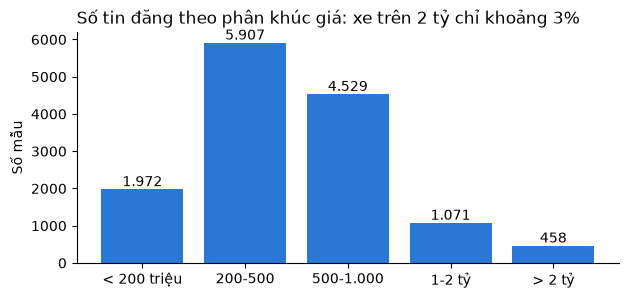

In [21]:
SEG_BINS = [0, 200, 500, 1000, 2000, np.inf]
SEG_LABELS = ["< 200 triệu", "200-500", "500-1.000", "1-2 tỷ", "> 2 tỷ"]
df["segment"] = pd.cut(df["price_tr"], bins=SEG_BINS, labels=SEG_LABELS, right=False)

seg = df["segment"].value_counts().reindex(SEG_LABELS)
tbl = pd.DataFrame({"số mẫu": seg, "%": (seg / len(df) * 100).round(1),
                    "gấp (so với phân khúc lớn nhất)": (seg.max() / seg).round(1)})
display(tbl)

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(seg.index.astype(str), seg.values, color=BLUE)
for x, v in enumerate(seg.values):
    ax.text(x, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")
ax.set_title("Số tin đăng theo phân khúc giá: xe trên 2 tỷ chỉ khoảng 3%", loc="left")
ax.set_ylabel("Số mẫu")
save(fig, "p04_phan_khuc_gia"); plt.show()

Phân khúc `> 2 tỷ` ít hơn phân khúc lớn nhất khoảng 10 lần trở lên → mất cân bằng thật sự. Ngoài ra các **đặc trưng** cũng lệch (xem bên dưới), đặc biệt `condition_ad` (xe mới chỉ ~9%), `fuel` (Hybrid ~2%) và `gearbox` (bán tự động <1%).

In [22]:
for col in ["fuel", "gearbox", "condition_ad"]:
    vc = df[col].value_counts()
    print(f"--- {col} ---")
    print(pd.DataFrame({"số mẫu": vc, "%": (vc / vc.sum() * 100).round(1)}), "\n")

--- fuel ---
                số mẫu     %
fuel                        
Xăng             10175  73.0
Dầu               2424  17.4
Điện              1035   7.4
Động cơ Hybrid     303   2.2 

--- gearbox ---
             số mẫu     %
gearbox                  
Tự động       11054  79.3
Số sàn         2785  20.0
Bán tự động      98   0.7 

--- condition_ad ---
              số mẫu     %
condition_ad              
Đã sử dụng     12757  91.5
Mới             1180   8.5 



### 8.2 Chia train/test, mã hóa, chuẩn hóa (thực hiện ở `model.ipynb`)
Các bước này phụ thuộc vào mô hình nên **không** làm ở notebook này (tránh hai phiên bản khác nhau). Nguyên tắc được dùng:

- **Chia 80/20, phân tầng theo phân khúc giá** (`random_state = 42`). Chia ngẫu nhiên thông thường có thể để tập test gần như không có xe > 2 tỷ, khiến điểm đánh giá nhìn đẹp nhưng không phản ánh khả năng với xe sang. Phân tầng đảm bảo mỗi phân khúc có cùng tỉ lệ ở cả hai tập. Tập test giữ nguyên phân phối thật, **không** cân bằng lại.
- **Không dùng tập validation riêng:** tham số được chọn bằng 5-fold cross-validation (hoặc OOB với Random Forest) **trên tập train**. Với ~14 nghìn dòng và chỉ ~460 xe trên 2 tỷ, CV ổn định hơn một tập validation cố định. Tập test chỉ dùng **một lần** để báo cáo kết quả cuối.
- **Đặc trưng:** chỉ gồm thông tin người mua thấy trong tin đăng. Không đưa `price_tr`, `price_log` (đáp án) và `mfdate` (trùng `age`); `carbrand`/`carmodel` thay bằng bản đã gộp nhãn (`*_grp`).
- **One-hot** cho biến phân loại: hãng, dòng xe, nhiên liệu... không có thứ tự (Toyota không "lớn hơn" Ford); mã hóa 0, 1, 2... sẽ tạo thứ bậc giả. `handle_unknown="ignore"` để nhãn lạ ở test không gây lỗi.
- **StandardScaler** cho biến số: cần cho mô hình dựa trên gradient/khoảng cách (Ridge); mô hình cây không cần nhưng không bị hại.
- Bộ mã hóa/chuẩn hóa **fit chỉ trên train rồi áp lên test**, để thống kê của test không rò rỉ vào huấn luyện.

### 8.3 Kỹ thuật xử lý mất cân bằng: thử ở đâu và quyết định cho file xuất
| Kỹ thuật | Ý tưởng |
|---|---|
| **Log giá + chia phân tầng** (dùng) | log đưa phân phối giá về gần đối xứng; phân tầng giữ đủ xe hiếm ở cả train và test |
| **Trọng số mẫu** (`sample_weight`) | mẫu thuộc phân khúc hiếm có trọng số lớn hơn (nghịch đảo căn bậc hai tần suất) |
| **Random Oversampling** | nhân bản ngẫu nhiên mẫu của phân khúc hiếm trong phần train |
| **Random Undersampling** | bỏ bớt mẫu ở phân khúc đông (đối chứng, thường làm mất thông tin) |

Ba kỹ thuật sau được thử ở `model.ipynb` (mục 7) bằng **cross-validation trên tập train**, việc cân bằng chỉ áp dụng trong phần train của từng fold, và phải thử trên chính mô hình cuối thì kết luận mới có giá trị.

**Quyết định cho file xuất ra:** `clean_data_oto.csv` **chỉ chứa dữ liệu thật**, không nhân bản hay chèn mẫu tổng hợp. Nếu ghi mẫu nhân bản vào file, người dùng sau chia ngẫu nhiên sẽ khiến bản sao của cùng một xe nằm ở cả train lẫn test, làm điểm đánh giá cao ảo. Khi báo cáo kết quả, **nêu MAPE theo từng phân khúc** chứ không chỉ một con số trung bình.

## 9. Kiểm tra cuối và xuất file

In [23]:
FINAL_COLS = ["carbrand", "carbrand_grp", "carmodel", "carmodel_grp", "carorigin", "condition_ad",
              "gearbox", "fuel", "cartype", "carseats", "mfdate", "age",
              "mileage_km", "mileage_missing", "km_per_year", "province", "price_tr", "price_log"]
clean = df[FINAL_COLS].copy()

assert clean.isna().sum().sum() == 0, "Còn giá trị thiếu"
assert (clean["price_tr"] >= 20).all() and (clean["mileage_km"] >= 0).all()
assert np.isfinite(clean["price_log"]).all()
assert not ((clean["condition_ad"] == "Mới") & (clean["age"] > 3)).any(), "Còn xe 'Mới' quá 3 năm tuổi"
assert (clean.loc[clean["condition_ad"] == "Mới", "mileage_missing"] == 0).all()

print("Kích thước raw  :", raw.shape)
print("Kích thước clean:", clean.shape, f"(giữ {len(clean) / len(raw):.1%} số dòng)")
clean.dtypes.to_frame("dtype").T

Kích thước raw  : (14835, 14)
Kích thước clean: (13937, 18) (giữ 93.9% số dòng)


,carbrand,carbrand_grp,carmodel,carmodel_grp,carorigin,condition_ad,gearbox,fuel,cartype,carseats,mfdate,age,mileage_km,mileage_missing,km_per_year,province,price_tr,price_log
dtype,str,str,str,str,str,str,str,str,str,int64,int64,int64,float64,int64,float64,str,float64,float64


In [24]:
clean.to_csv("clean_data_oto.csv", index=False)   # utf-8, để các notebook khác đọc mặc định được

check = pd.read_csv("clean_data_oto.csv")
print("Đọc lại:", check.shape, "| thiếu:", int(check.isna().sum().sum()))
check.head()

Đọc lại: (13937, 18) | thiếu: 0


,carbrand,carbrand_grp,carmodel,carmodel_grp,carorigin,condition_ad,gearbox,fuel,cartype,carseats,mfdate,age,mileage_km,mileage_missing,km_per_year,province,price_tr,price_log
0,Toyota,Toyota,Vios,Toyota Vios,Việt Nam,Đã sử dụng,Tự động,Xăng,Sedan,5,2018,8,109366.0,0,13670.750000,can-tho,309.0,5.733341
1,Peugeot,Peugeot,3008,Peugeot 3008,Việt Nam,Đã sử dụng,Tự động,Xăng,SUV / Cross over,5,2022,4,30000.0,0,7500.000000,da-nang,697.0,6.546785
2,Toyota,Toyota,Fortuner,Toyota Fortuner,Nước khác,Đã sử dụng,Tự động,Xăng,SUV / Cross over,7,2018,8,90000.0,0,11250.000000,can-tho,650.0,6.476972
3,Kia,Kia,Sorento,Kia Sorento,Nước khác,Đã sử dụng,Tự động,Dầu,SUV / Cross over,7,2022,4,112000.0,0,28000.000000,binh-duong,810.0,6.697034
4,Toyota,Toyota,Camry,Toyota Camry,Không rõ,Đã sử dụng,Tự động,Xăng,Sedan,5,2014,12,100000.0,0,8333.333333,dong-thap,325.0,5.783825


### Số tin còn lại qua từng bước làm sạch
Chỉ các bước **loại dòng** làm giảm số tin; các bước khác (sửa nhãn "Mới", chuyển km vô lý thành thiếu, điền thiếu, gộp nhãn) giữ nguyên số dòng.

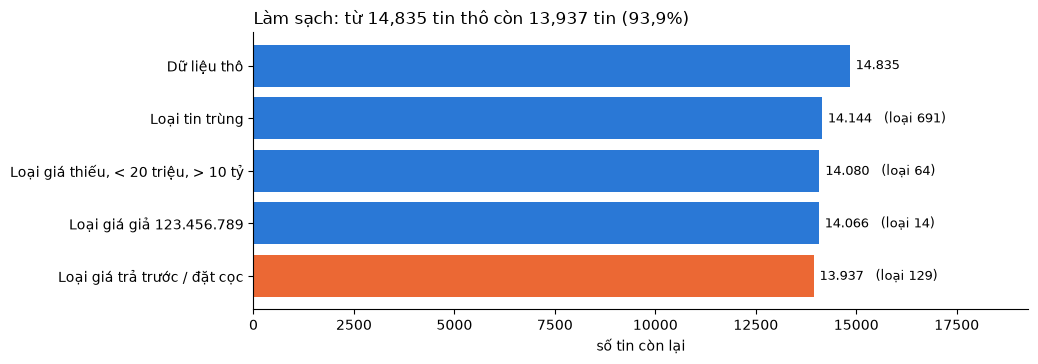

,bước,còn lại,loại bỏ
0,Dữ liệu thô,14835,0
1,Loại tin trùng,14144,691
2,"Loại giá thiếu, < 20 triệu, > 10 tỷ",14080,64
3,Loại giá giả 123.456.789,14066,14
4,Loại giá trả trước / đặt cọc,13937,129


In [25]:
steps = pd.DataFrame(FUNNEL, columns=["bước", "còn lại"])
steps["loại bỏ"] = (-steps["còn lại"].diff()).fillna(0).astype(int)
assert steps["còn lại"].iloc[-1] == len(clean)


def vn(x):
    return f"{x:,}".replace(",", ".")


fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(steps))[::-1]
ax.barh(y, steps["còn lại"], color=[BLUE] * (len(steps) - 1) + [ORANGE])
for yi, (_, r) in zip(y, steps.iterrows()):
    note = f"   (loại {vn(r['loại bỏ'])})" if r["loại bỏ"] else ""
    ax.text(r["còn lại"] + 150, yi, vn(r["còn lại"]) + note, va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(steps["bước"])
ax.set_xlim(0, steps["còn lại"].max() * 1.3); ax.set_xlabel("số tin còn lại")
ax.set_title(f"Làm sạch: từ {vn(steps['còn lại'].iloc[0])} tin thô còn {vn(len(clean))} tin "
             f"({len(clean) / steps['còn lại'].iloc[0]:.1%})".replace(".", ","), loc="left")
ax.grid(axis="y", visible=False)
save(fig, "p01_pheu_lam_sach"); plt.show()
steps

In [26]:
clean.describe(include="all").T.round(1)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
carbrand,13937,69,Toyota,2826,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carbrand_grp,13937,28,Toyota,2826,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carmodel,13937,466,Innova,582,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carmodel_grp,13937,214,Toyota Innova,582,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carorigin,13937,11,Không rõ,5787,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition_ad,13937,2,Đã sử dụng,12757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gearbox,13937,3,Tự động,11054,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel,13937,4,Xăng,10175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cartype,13937,10,SUV / Cross over,5424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carseats,13937.0,NaN,NaN,NaN,5.795293,1.739924,2.0,5.0,5.0,7.0,16.0


## Tóm tắt các bước đã làm

| Mục | Bước | Kết quả |
|---|---|---|
| 0 | Đọc code crawl: `N/A` = không có thẻ, cột chọn từ danh sách vs. gõ tự do, URL chứa vị trí | Biết mỗi loại lỗi đến từ đâu |
| 2 | Đổi `N/A`/`Đang cập nhật`/`Khác (carseats)` → thiếu thật, ép kiểu số | Cột số dùng được |
| 3 | Trích `province` (tỉnh/thành, slug) từ URL, không tách quận/huyện vì quá thưa; bỏ `no`, `url`, `veh_warranty_policy`; xóa dòng trùng (không xét vị trí) | Bớt cột vô ích, tránh trùng mẫu giữa train và test |
| 5 | Loại giá < 20 triệu hoặc > 10 tỷ, giá giả dạng `123.456.789`; số km vô lý → thiếu; xe "Mới" hơn 3 năm tuổi → "Đã sử dụng" | Bỏ lỗi nhập liệu, giữ xe sang thật |
| 5.1 | Loại giá < 30% trung vị xe cùng hãng-dòng-năm (giá trả trước / đặt cọc) | Bỏ nhãn sai, chủ yếu ở phân khúc < 200 triệu |
| 6 | Xe mới: km = 0; xe cũ: trung vị theo đời xe + cột `mileage_missing` | Phản ánh đúng bản chất thiếu, mô hình biết dòng nào là ước lượng |
| 6 | `carseats`: mode theo dòng xe → hãng; `cartype`: mode theo dòng xe, còn lại "Không rõ" | Chỉ điền khi có căn cứ |
| 6 | `carorigin` thiếu ~40% → nhãn "Không rõ" | Không bịa thông tin |
| 7 | log(giá); gộp nhãn hiếm theo cấp dòng → hãng → nhóm hãng (cao cấp / phổ thông), ngưỡng chọn bằng CV trên train; `age`, `km_per_year` | Giảm lệch, giảm số chiều nhưng giữ thông tin hãng; cải thiện rõ ở xe > 2 tỷ |
| 8 | Mất cân bằng theo phân khúc giá: chia phân tầng + log giá; trọng số mẫu / oversampling / undersampling thử ở `model.ipynb` bằng CV trên train | Không dùng tập test để ra quyết định |
| 9 | Xuất `clean_data_oto.csv`, kiểm tra bằng `assert` | Không thiếu, không nhân bản dữ liệu |